# Category A/B COE Premium Trends: Austin's Extended Investigation

**Author/workstream:** Lew Wai Loon (Austin), trend analysis | Team Godex

This notebook records the detailed investigation behind the trend contribution to the team project. It includes descriptive comparisons, policy-date sensitivity checks and exploratory mean-shift analysis. The selected team findings and final recommendation are presented in [main.ipynb](main.ipynb).

**Data period:** January 2010-October 2026. Run with Python 3.14 from the repository root.

## 1. Setup & Imports

Python 3.14, NumPy, pandas and Matplotlib support the analysis. Random seeds are fixed for reproducible simulation results.

In [2]:
import sys
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import StrMethodFormatter

# Add other libraries here, e.g.
# import seaborn as sns
# from sklearn.linear_model import LinearRegression

In [3]:
# Python version check: the judges' environment uses Python 3.14
print(f"Python version: {sys.version.split()[0]}")
if sys.version_info[:2] != (3, 14):
    print("WARNING: this notebook will be run on Python 3.14. Please test it on 3.14 before submitting.")

Python version: 3.14.2


In [4]:
# Random seed: keep this so your results are reproducible
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
# If you use other libraries with randomness, set their seeds too,
# e.g. random_state=SEED in scikit-learn models

In [5]:
# Display settings (optional)
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (10, 5)

## 2. Data Ingestion

Load the two provided CSV files from `data/` using relative paths. Run the notebook from the project root (the folder containing `data/`).

Read all columns as strings for now and represent blank fields as missing (`pd.NA`). Dates and numeric columns will be converted explicitly in Section 3. In particular, a blank registration count is **not** treated as zero.

COE data supports our main trend analysis. Registration data provides supporting market context; it does not identify each car's COE category and covers a shorter period. Keep all categories and all available dates at this stage.

In [6]:
DATA_DIR = Path("data")
source_paths = {
    "COE bidding results": DATA_DIR / "COEBiddingResultsPrices.csv",
    "Car registrations": DATA_DIR / "NewRegistrationofCarsbyMake.csv",
}

for dataset, path in source_paths.items():
    if not path.is_file():
        raise FileNotFoundError(
            f"Cannot find {dataset}: {path}. "
            "Run this notebook from the project root containing data/."
        )

# Only empty fields are marked missing. Do not fill or drop rows here.
read_options = {"dtype": "string", "keep_default_na": False, "na_values": [""]}
coe = pd.read_csv(source_paths["COE bidding results"], **read_options)
registrations = pd.read_csv(source_paths["Car registrations"], **read_options)

loaded_data = {
    "COE bidding results": coe,
    "Car registrations": registrations,
}

In [7]:
# YYYY-MM month strings sort chronologically; date conversion comes in Section 3.
data_overview = pd.DataFrame([
    {
        "dataset": name,
        "rows": len(frame),
        "columns": frame.shape[1],
        "first_month": frame["month"].min(),
        "last_month": frame["month"].max(),
        "unique_months": frame["month"].nunique(),
    }
    for name, frame in loaded_data.items()
]).set_index("dataset")
data_overview

,rows,columns,first_month,last_month,unique_months
dataset,,,,,
COE bidding results,1990,7,2010-01,2026-10,199
Car registrations,51669,6,2016-01,2025-05,113


In [8]:
# Preview the COE auction records, including all vehicle categories.
coe.head()

,month,bidding_no,vehicle_class,quota,bids_success,bids_received,premium
0,2010-01,1,Category A,1152,1145,1342,18502
1,2010-01,1,Category B,687,679,883,19190
2,2010-01,1,Category C,173,173,265,19001
3,2010-01,1,Category D,373,365,509,889
4,2010-01,1,Category E,586,567,1011,19889


In [9]:
# Preview registrations by make, fuel type, importer type and body type.
registrations.head()

,month,make,importer_type,fuel_type,vehicle_type,number
0,2016-01,ALFA ROMEO,<NA>,Petrol,Hatchback,3
1,2016-01,ALPINA,<NA>,Petrol,Hatchback,0
2,2016-01,ASTON MARTIN,<NA>,Petrol,Hatchback,0
3,2016-01,AUDI,<NA>,Petrol,Hatchback,45
4,2016-01,B.M.W.,<NA>,Petrol,Hatchback,5


In [10]:
# Inspect missingness without changing the source values.
ingestion_audit = pd.DataFrame([
    {
        "dataset": name,
        "column": column,
        "dtype": str(frame[column].dtype),
        "missing_rows": int(frame[column].isna().sum()),
        "missing_pct": round(frame[column].isna().mean() * 100, 2),
    }
    for name, frame in loaded_data.items()
    for column in frame.columns
])
ingestion_audit

,dataset,column,dtype,missing_rows,missing_pct
0,COE bidding results,month,string,0,0.00
1,COE bidding results,bidding_no,string,0,0.00
2,COE bidding results,vehicle_class,string,0,0.00
3,COE bidding results,quota,string,0,0.00
4,COE bidding results,bids_success,string,0,0.00
5,COE bidding results,bids_received,string,0,0.00
6,COE bidding results,premium,string,0,0.00
7,Car registrations,month,string,0,0.00
8,Car registrations,make,string,0,0.00
9,Car registrations,importer_type,string,31155,60.30


**Before cleaning:** Check the coverage and missingness tables above. A missing `number` in the registration file remains unknown; an explicit `0` remains zero. Do not limit the COE trend analysis to the shorter registration coverage. Only analyses joining both datasets need the overlapping months. No dates, amounts or categories have been cleaned or filtered in this section.

## 3. Data Cleaning

Preserve raw inputs, standardise text and numeric fields, validate keys and retain unknown registration counts. The two datasets overlap from January 2016 to May 2025; COE-only comparisons retain the longer COE history.

### 3.1 Preserve the inputs and standardise text

**Why:** Keep the original imported tables for comparison. Strip surrounding whitespace and represent empty text as missing so formatting differences do not create false categories or keys. Our trend analysis uses the full COE history; registrations receive basic cleaning only and are not joined here.

In [11]:
coe_clean = coe.copy(deep=True)
registrations_clean = registrations.copy(deep=True)

for frame in [coe_clean, registrations_clean]:
    for column in frame.columns:
        frame[column] = frame[column].str.strip().replace("", pd.NA)

### 3.2 Convert months and numeric fields

**Why:** Dates must sort chronologically, and numeric values must support arithmetic. Some COE bid counts include thousands separators (for example, `"1,438"`). Remove those commas before converting. Raise an error on malformed values rather than silently losing them. Nullable integers preserve unknown registration counts as `pd.NA` while keeping explicit zeroes.

`month` is stored as the first day of its month for plotting and sorting; this is a month label, not the actual auction date. `bidding_no` gives the order within the month.

In [12]:
coe_clean["month"] = pd.to_datetime(coe_clean["month"], format="%Y-%m", errors="raise")
registrations_clean["month"] = pd.to_datetime(
    registrations_clean["month"], format="%Y-%m", errors="raise"
)

coe_numeric_columns = ["bidding_no", "quota", "bids_success", "bids_received", "premium"]
comma_counts = coe_clean[coe_numeric_columns].apply(
    lambda column: column.str.contains(",", regex=False, na=False).sum()
).rename("rows_with_commas_removed")

for column in coe_numeric_columns:
    values = coe_clean[column].str.replace(",", "", regex=False)
    coe_clean[column] = pd.to_numeric(values, errors="raise").astype("Int64")

registrations_clean["number"] = pd.to_numeric(
    registrations_clean["number"], errors="raise"
).astype("Int64")
comma_counts.to_frame()

,rows_with_commas_removed
bidding_no,0
quota,0
bids_success,41
bids_received,109
premium,0


### 3.3 Handle duplicates and validate the records

**Why:** Duplicate records would distort prices, counts and comparisons. Remove only fully identical rows and report how many were removed. Conflicting records sharing a key require investigation, so the checks stop execution instead of choosing one arbitrarily. Check categories, missing COE values and count relationships before calculating ratios.

No COE values are imputed. Unknown registration counts and importer types remain missing. Missing importer types do not invalidate the other information in their rows.

In [13]:
coe_duplicates_removed = int(coe_clean.duplicated().sum())
registration_duplicates_removed = int(registrations_clean.duplicated().sum())
coe_clean = coe_clean.drop_duplicates().reset_index(drop=True)
registrations_clean = registrations_clean.drop_duplicates().reset_index(drop=True)

coe_key = ["month", "bidding_no", "vehicle_class"]
registration_key = ["month", "make", "importer_type", "fuel_type", "vehicle_type"]
expected_categories = {f"Category {letter}" for letter in "ABCDE"}

assert not coe_clean.duplicated(coe_key).any(), "Conflicting COE records share a key."
assert not registrations_clean.duplicated(registration_key).any(), "Conflicting registration records share a key."
assert coe_clean.notna().all().all(), "COE fields contain missing values; investigate before analysis."
assert registrations_clean["month"].notna().all(), "Registration months are missing."
assert set(coe_clean["vehicle_class"]) == expected_categories, "Unexpected COE categories."
assert coe_clean["bidding_no"].isin([1, 2]).all(), "Unexpected bidding exercise number."
assert coe_clean[coe_numeric_columns].ge(0).all().all(), "Negative COE values found."
assert coe_clean["quota"].gt(0).all(), "Zero quota would make bidding pressure undefined."
assert coe_clean["premium"].gt(0).all(), "Zero premium would make the percentage gap undefined."
assert coe_clean["bids_success"].le(coe_clean["quota"]).all(), "Successful bids exceed quota."
assert coe_clean["bids_success"].le(coe_clean["bids_received"]).all(), "Successful bids exceed bids received."
assert registrations_clean["number"].dropna().ge(0).all(), "Negative registration counts found."

coe_clean = coe_clean.sort_values(coe_key).reset_index(drop=True)
registrations_clean = registrations_clean.sort_values(registration_key).reset_index(drop=True)

print(f"Identical COE rows removed: {coe_duplicates_removed}")
print(f"Identical registration rows removed: {registration_duplicates_removed}")
print(f"Unknown registration counts retained: {registrations_clean['number'].isna().sum():,}")
print(f"Explicit zero registration counts retained: {registrations_clean['number'].eq(0).sum():,}")

Identical COE rows removed: 0
Identical registration rows removed: 0
Unknown registration counts retained: 29,463
Explicit zero registration counts retained: 6,390


### 3.4 Check exercise coverage and preserve absent months

**Why:** An exercise is identified by `month` plus `bidding_no`, with one row per category. Confirm this structure before pairing A and B. Report months absent from the file and keep them absent; filling them would invent auction results. The month label must not be mistaken for an exact auction date.

In [14]:
round_category_counts = coe_clean.groupby(["month", "bidding_no"])["vehicle_class"].nunique()
assert round_category_counts.eq(5).all(), "An exercise does not contain all five categories."

coe_rounds = coe_clean[["month", "bidding_no"]].drop_duplicates().reset_index(drop=True)
observed_months = pd.PeriodIndex(coe_clean["month"].dt.to_period("M").unique()).sort_values()
calendar_months = pd.period_range(observed_months.min(), observed_months.max(), freq="M")
missing_coe_months = calendar_months.difference(observed_months)

print(f"COE records retained: {len(coe_clean):,}")
print(f"Distinct bidding exercises: {len(coe_rounds):,}")
print(f"Observed months: {len(observed_months):,}")
print("Months absent from the COE file:", ", ".join(missing_coe_months.astype(str)))
print("No auction records or prices have been filled in for absent months.")

COE records retained: 1,990
Distinct bidding exercises: 398
Observed months: 199
Months absent from the COE file: 2020-04, 2020-05, 2020-06
No auction records or prices have been filled in for absent months.


### 3.5 Prepare paired A/B observations and trend measures

**Why:** Compare Category A and Category B from the same exercise, preserving all available COE dates. Positive gaps mean B costs more; negative gaps mean A costs more. Expressing the gap as a percentage of B helps compare periods with different price levels. Bids per quota measure bidding pressure and are available only after an exercise closes; they can explain the same exercise but cannot forecast it.

Both strict (`A > B`) and inclusive (`A >= B`) indicators are retained so later charts can state their definition precisely. No registration join or monthly registration aggregation is needed for this COE-only workstream. Any future join must aggregate registrations appropriately first and use only the overlapping period, January 2016 to May 2025 (with absent COE months still excluded).

In [15]:
coe_ab = coe_clean.loc[coe_clean["vehicle_class"].isin(["Category A", "Category B"])].copy()
coe_ab["category"] = coe_ab["vehicle_class"].map({"Category A": "a", "Category B": "b"})

paired_metrics = ["premium", "quota", "bids_success", "bids_received"]
ab_trends = coe_ab.pivot(
    index=["month", "bidding_no"], columns="category", values=paired_metrics
)
ab_trends.columns = [f"{metric}_{category}" for metric, category in ab_trends.columns]
ab_trends = ab_trends.reset_index().sort_values(["month", "bidding_no"]).reset_index(drop=True)

assert len(ab_trends) == len(coe_rounds), "A/B pairing lost bidding exercises."
assert ab_trends.notna().all().all(), "A/B pairing contains missing observations."

ab_trends["gap_sgd"] = ab_trends["premium_b"] - ab_trends["premium_a"]
ab_trends["gap_pct_of_b"] = ab_trends["gap_sgd"] / ab_trends["premium_b"] * 100
for category in ["a", "b"]:
    ab_trends[f"bids_to_quota_{category}"] = (
        ab_trends[f"bids_received_{category}"] / ab_trends[f"quota_{category}"]
    )
ab_trends["a_exceeds_b"] = ab_trends["premium_a"] > ab_trends["premium_b"]
ab_trends["a_at_least_b"] = ab_trends["premium_a"] >= ab_trends["premium_b"]

ab_trends.head()

,month,bidding_no,premium_a,premium_b,quota_a,quota_b,bids_success_a,bids_success_b,bids_received_a,bids_received_b,gap_sgd,gap_pct_of_b,bids_to_quota_a,bids_to_quota_b,a_exceeds_b,a_at_least_b
0,2010-01-01,1,18502,19190,1152,687,1145,679,1342,883,688,3.585201,1.164931,1.285298,False,False
1,2010-01-01,2,20501,22400,1151,717,1149,717,1673,1105,1899,8.477679,1.453519,1.541144,False,False
2,2010-02-01,1,19989,23180,1154,1154,1153,690,1326,930,3191,13.766178,1.149047,0.805893,False,False
3,2010-02-01,2,20340,23889,1148,685,1148,658,1493,956,3549,14.85621,1.300523,1.39562,False,False
4,2010-03-01,1,20802,26389,1148,688,1141,667,1758,1087,5587,21.1717,1.531359,1.579942,False,False


### 3.6 Summarise the cleaned outputs

**Why:** Make the retained rows, coverage and remaining missing fields visible before analysis. `coe_clean` keeps all five categories, while `ab_trends` is the table to use for Austin's trend analysis. Unknown registration fields remain visible in `registrations_clean`; they have not been filled, dropped or used to restrict the COE history.

In [16]:
cleaning_summary = pd.DataFrame([
    {
        "table": name,
        "rows": len(frame),
        "first_month": frame["month"].min().strftime("%Y-%m"),
        "last_month": frame["month"].max().strftime("%Y-%m"),
        "missing_cells": int(frame.isna().sum().sum()),
    }
    for name, frame in {
        "coe_clean": coe_clean,
        "registrations_clean": registrations_clean,
        "ab_trends": ab_trends,
    }.items()
]).set_index("table")
cleaning_summary

,rows,first_month,last_month,missing_cells
table,,,,
coe_clean,1990,2010-01,2026-10,0
registrations_clean,51669,2016-01,2025-05,60618
ab_trends,398,2010-01,2026-10,0


## 4. Exploratory Data Analysis

Examine premiums, signed gaps, price reversals and policy-date comparisons. Definition changes and missing bidding months provide historical context without establishing causation.

**Policy dates marked on the charts (effective exercises, not announcement dates):**
- **February 2014, exercise 1:** Category A added a 97 kW maximum-power limit alongside the existing 1,600 cc engine-size limit.
- **May 2022, exercise 1:** Category A's maximum power for fully electric cars increased from 97 to 110 kW; non-fully electric limits stayed unchanged.

[LTA's vehicle statistics notes](https://www.lta.gov.sg/content/dam/ltagov/who_we_are/statistics_and_publications/statistics/pdf/MVP02-1_New_Reg_by_COE.pdf) distinguish these three definition regimes (before February 2014; February 2014-April 2022; from May 2022). The SDS briefing mentions the 2014 change by year on slide 2; the group workplan identifies May 2022. The exact effective exercises were verified against official LTA sources.

The same LTA notes record a separate **6 August 2012 taxi change**: taxis ceased bidding for new Category A COEs and instead paid the Category A PQP. This is a potential demand-related policy event, rather than another passenger-car engine/power threshold change. The creation of the A/B split in 1999 predates our sample. The proposed 2026 merger is not treated as an implemented definition change.

An event marker identifies a possible break to investigate; it does not establish a statistical break or prove a causal effect. Registrations and individual model classifications are not observed in our COE table.

### 4.1 Category A and B premiums over time

**Purpose:** Compare both categories across the full available history before examining the gap separately. Each line uses the observed premium from every exercise, without smoothing.

The data contains months and exercise numbers, not exact auction dates. For visual spacing only, exercise 1 is placed at the start of each month and exercise 2 halfway through it. These positions are not actual auction dates. Missing months are inserted as empty plotting positions so lines do not connect across April-June 2020. No missing premiums are estimated. The shaded period marks those absent months, corresponding to the bidding suspension noted in the notebook brief.

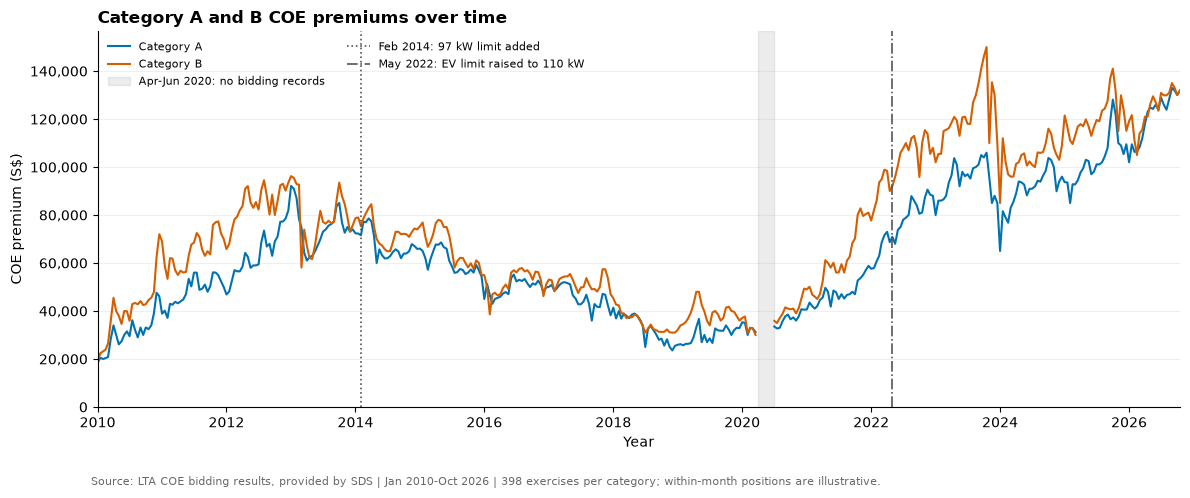

In [17]:
CAT_COLORS = {"Category A": "#0072B2", "Category B": "#D55E00"}

# Include empty plotting positions for missing exercises, without altering ab_trends.
plot_months = pd.date_range(
    ab_trends["month"].min(), ab_trends["month"].max(), freq="MS"
)
plot_index = pd.MultiIndex.from_product(
    [plot_months, [1, 2]], names=["month", "bidding_no"]
)
premium_plot = ab_trends.set_index(["month", "bidding_no"])[
    ["premium_a", "premium_b"]
].reindex(plot_index).reset_index()

month_duration = premium_plot["month"] + pd.offsets.MonthBegin(1) - premium_plot["month"]
premium_plot["plot_date"] = (
    premium_plot["month"]
    + month_duration * (premium_plot["bidding_no"] - 1) / 2
)

fig, ax = plt.subplots(figsize=(12, 5))
for category, column in [("Category A", "premium_a"), ("Category B", "premium_b")]:
    ax.plot(
        premium_plot["plot_date"],
        premium_plot[column].to_numpy(dtype=float, na_value=np.nan),
        label=category, color=CAT_COLORS[category], linewidth=1.5,
    )

ax.axvspan(
    pd.Timestamp("2020-04-01"), pd.Timestamp("2020-07-01"),
    color="grey", alpha=0.15, label="Apr-Jun 2020: no bidding records",
)
ax.set_title("Category A and B COE premiums over time", loc="left", fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("COE premium (S$)")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_ylim(bottom=0)
ax.set_xlim(premium_plot["plot_date"].min(), premium_plot["plot_date"].max())
ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
ax.axvline(pd.Timestamp("2014-02-01"), color="#555555", linestyle=":", linewidth=1.2,
           label="Feb 2014: 97 kW limit added")
ax.axvline(pd.Timestamp("2022-05-01"), color="#555555", linestyle="-.", linewidth=1.2,
           label="May 2022: EV limit raised to 110 kW")
ax.legend(loc="upper left", frameon=False, ncol=2, fontsize=8)
fig.text(
    0.08, 0.02,
    "Source: LTA COE bidding results, provided by SDS | Jan 2010-Oct 2026 | "
    "398 exercises per category; within-month positions are illustrative.",
    fontsize=8, color="dimgray",
)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

**Takeaway:** Both categories' premiums are much higher at the end of the sample than at the start, and their prices are very close in the latest exercises. This chart alone does not establish whether the convergence will persist.

### 4.2 The A/B premium gap in dollars and as a percentage of B

**Purpose:** Make changes in the separation between the categories visible. The dollar gap is `premium_b - premium_a`; the percentage gap divides this difference by `premium_b` and multiplies by 100. Above zero means B is more expensive, below zero means A is more expensive, and zero means equal premiums.

Use the same month-based plotting convention as 4.1. Empty positions preserve the April-June 2020 gap without inventing prices. Both panels show individual exercises with no smoothing. Percentage values describe the gap relative to B's price, not premium growth over time.

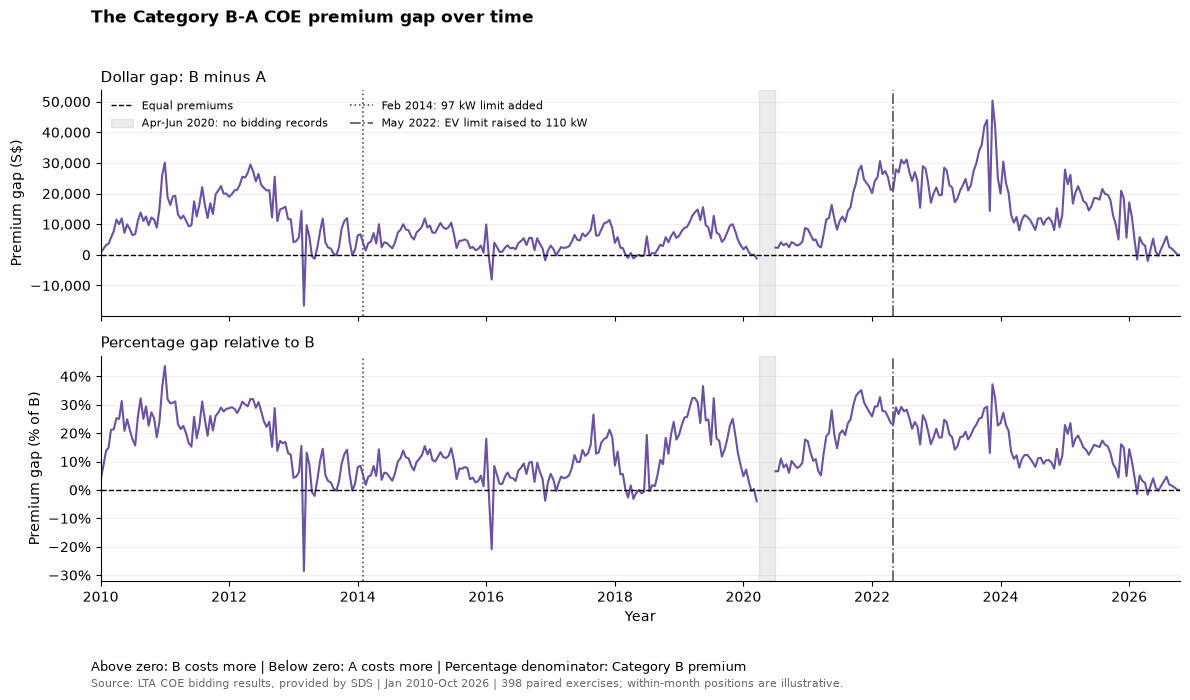

In [18]:
# Build this chart directly from the cleaned paired observations.
gap_months = pd.date_range(
    ab_trends["month"].min(), ab_trends["month"].max(), freq="MS"
)
gap_index = pd.MultiIndex.from_product(
    [gap_months, [1, 2]], names=["month", "bidding_no"]
)
gap_plot = ab_trends.set_index(["month", "bidding_no"])[
    ["gap_sgd", "gap_pct_of_b"]
].reindex(gap_index).reset_index()

gap_month_duration = gap_plot["month"] + pd.offsets.MonthBegin(1) - gap_plot["month"]
gap_plot["plot_date"] = (
    gap_plot["month"]
    + gap_month_duration * (gap_plot["bidding_no"] - 1) / 2
)

gap_fig, gap_axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
gap_panels = [
    ("gap_sgd", "Dollar gap: B minus A", "Premium gap (S$)", "{x:,.0f}"),
    ("gap_pct_of_b", "Percentage gap relative to B", "Premium gap (% of B)", "{x:.0f}%"),
]
for ax, (column, title, ylabel, number_format) in zip(gap_axes, gap_panels):
    values = gap_plot[column].to_numpy(dtype=float, na_value=np.nan)
    ax.plot(gap_plot["plot_date"], values, color="#6A51A3", linewidth=1.5)
    ax.axhline(0, color="black", linewidth=1, linestyle="--", label="Equal premiums")
    ax.axvspan(
        pd.Timestamp("2020-04-01"), pd.Timestamp("2020-07-01"),
        color="grey", alpha=0.15, label="Apr-Jun 2020: no bidding records",
    )
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_ylabel(ylabel)
    ax.yaxis.set_major_formatter(StrMethodFormatter(number_format))
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlim(gap_plot["plot_date"].min(), gap_plot["plot_date"].max())

for ax in gap_axes:
    ax.axvline(pd.Timestamp("2014-02-01"), color="#555555", linestyle=":", linewidth=1.2,
               label="Feb 2014: 97 kW limit added")
    ax.axvline(pd.Timestamp("2022-05-01"), color="#555555", linestyle="-.", linewidth=1.2,
               label="May 2022: EV limit raised to 110 kW")
gap_axes[0].legend(loc="upper left", frameon=False, fontsize=8, ncol=2)
gap_axes[1].xaxis.set_major_locator(mdates.YearLocator(2))
gap_axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
gap_axes[1].set_xlabel("Year")
gap_fig.suptitle("The Category B-A COE premium gap over time", x=0.08, ha="left", fontweight="bold")
gap_fig.text(
    0.08, 0.035,
    "Above zero: B costs more | Below zero: A costs more | Percentage denominator: Category B premium",
    fontsize=9,
)
gap_fig.text(
    0.08, 0.012,
    "Source: LTA COE bidding results, provided by SDS | Jan 2010-Oct 2026 | "
    "398 paired exercises; within-month positions are illustrative.",
    fontsize=8, color="dimgray",
)
gap_fig.tight_layout(rect=(0, 0.08, 1, 0.96))
plt.show()

**Takeaway:** The gap has fluctuated substantially and is close to zero in the latest exercises; in October 2026's second exercise it is -S$103 (about -0.08% of B), meaning A costs slightly more. This descriptive chart does not establish whether the convergence is permanent.

### 4.3 How often Category A costs more than Category B

**Purpose:** Check whether A being more expensive is an isolated event or occurs repeatedly. For each observed exercise, count the exercises with `premium_a > premium_b` in the current exercise and the previous 23, then divide by 24 and multiply by 100. For example, 6 reversals out of 24 gives 25%. Equal premiums do not count as A being more expensive.

A full window is required, so the first 23 observations have no rolling estimate. Twenty-four exercises are roughly a year, but the calendar span is longer when bidding is suspended. Calculate the rolling statistic over observed exercises first, then insert empty plotting positions for absent months to avoid drawing through the suspension. Missing exercises are not counted as zero reversals. This describes past exercises; it is not a forecast probability.

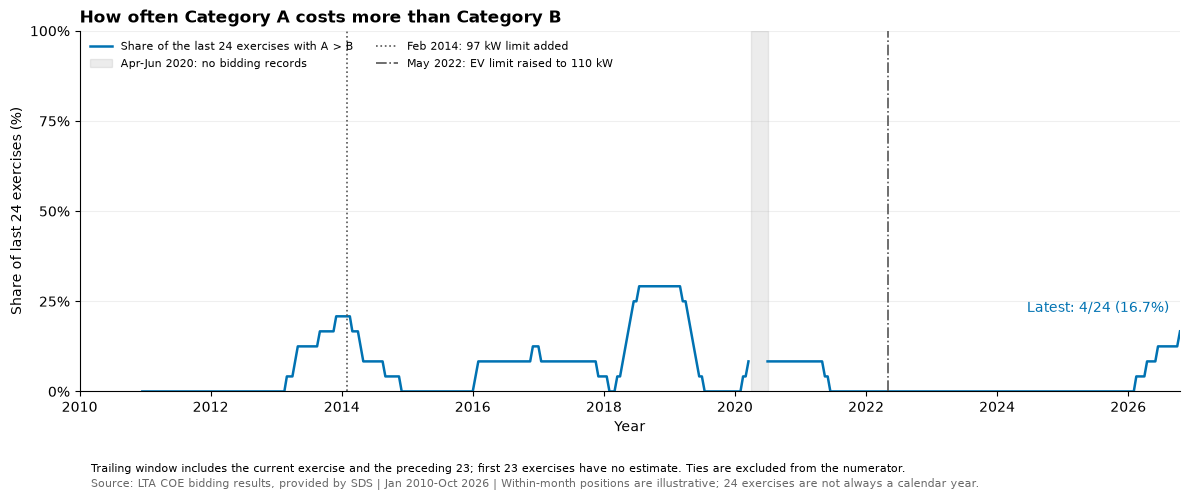

In [19]:
REVERSAL_WINDOW = 24
reversal_trend = ab_trends[["month", "bidding_no", "a_exceeds_b"]].copy()
reversal_trend = reversal_trend.sort_values(["month", "bidding_no"]).reset_index(drop=True)
reversal_trend["a_higher_count_24"] = (
    reversal_trend["a_exceeds_b"].astype(int)
    .rolling(REVERSAL_WINDOW, min_periods=REVERSAL_WINDOW).sum()
    .astype("Int64")
)
reversal_trend["a_higher_share_24_pct"] = (
    reversal_trend["a_higher_count_24"] / REVERSAL_WINDOW * 100
)

reversal_months = pd.date_range(
    reversal_trend["month"].min(), reversal_trend["month"].max(), freq="MS"
)
reversal_index = pd.MultiIndex.from_product(
    [reversal_months, [1, 2]], names=["month", "bidding_no"]
)
reversal_plot = reversal_trend.set_index(["month", "bidding_no"])[
    ["a_higher_share_24_pct"]
].reindex(reversal_index).reset_index()
reversal_month_duration = (
    reversal_plot["month"] + pd.offsets.MonthBegin(1) - reversal_plot["month"]
)
reversal_plot["plot_date"] = (
    reversal_plot["month"]
    + reversal_month_duration * (reversal_plot["bidding_no"] - 1) / 2
)

reversal_fig, reversal_ax = plt.subplots(figsize=(12, 5))
reversal_ax.plot(
    reversal_plot["plot_date"],
    reversal_plot["a_higher_share_24_pct"].to_numpy(dtype=float, na_value=np.nan),
    color=CAT_COLORS["Category A"], linewidth=1.8,
    label="Share of the last 24 exercises with A > B",
)
reversal_ax.axvspan(
    pd.Timestamp("2020-04-01"), pd.Timestamp("2020-07-01"),
    color="grey", alpha=0.15, label="Apr-Jun 2020: no bidding records",
)
reversal_ax.set_title(
    "How often Category A costs more than Category B",
    loc="left", fontweight="bold",
)
reversal_ax.set_xlabel("Year")
reversal_ax.set_ylabel("Share of last 24 exercises (%)")
reversal_ax.set_ylim(0, 100)
reversal_ax.set_yticks([0, 25, 50, 75, 100])
reversal_ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.0f}%"))
reversal_ax.xaxis.set_major_locator(mdates.YearLocator(2))
reversal_ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
reversal_ax.set_xlim(reversal_plot["plot_date"].min(), reversal_plot["plot_date"].max())
reversal_ax.grid(axis="y", alpha=0.2)
reversal_ax.spines[["top", "right"]].set_visible(False)
reversal_ax.axvline(pd.Timestamp("2014-02-01"), color="#555555", linestyle=":", linewidth=1.2,
                    label="Feb 2014: 97 kW limit added")
reversal_ax.axvline(pd.Timestamp("2022-05-01"), color="#555555", linestyle="-.", linewidth=1.2,
                    label="May 2022: EV limit raised to 110 kW")
reversal_ax.legend(loc="upper left", frameon=False, ncol=2, fontsize=8)

latest_reversal_count = int(reversal_trend["a_higher_count_24"].iloc[-1])
latest_reversal_share = float(reversal_trend["a_higher_share_24_pct"].iloc[-1])
reversal_ax.annotate(
    f"Latest: {latest_reversal_count}/{REVERSAL_WINDOW} ({latest_reversal_share:.1f}%)",
    xy=(reversal_plot["plot_date"].iloc[-1], latest_reversal_share),
    xytext=(-8, 14), textcoords="offset points", ha="right", fontsize=10,
    color=CAT_COLORS["Category A"],
)
reversal_fig.text(
    0.08, 0.045,
    "Trailing window includes the current exercise and the preceding 23; "
    "first 23 exercises have no estimate. Ties are excluded from the numerator.",
    fontsize=8,
)
reversal_fig.text(
    0.08, 0.015,
    "Source: LTA COE bidding results, provided by SDS | Jan 2010-Oct 2026 | "
    "Within-month positions are illustrative; 24 exercises are not always a calendar year.",
    fontsize=8, color="dimgray",
)
reversal_fig.tight_layout(rect=(0, 0.09, 1, 1))
plt.show()

**Takeaway:** A costs more than B in 4 of the latest 24 exercises (16.7%), compared with 22 of all 398 exercises (5.5%). Reversals occur in the recent window, but B still costs more in most of those exercises. Overlapping rolling windows are descriptive, not independent evidence of a permanent change.

### 4.4 What changed around the definition changes?

**Method:** Start with the 24 observed exercises immediately before each effective exercise and the first 24 exercises under the new definition. Use equally sized windows so different sample lengths do not drive the comparison. Report the mean and median dollar gap, the mean percentage gap, and the share with A > B. These are descriptive comparisons, not tests of statistical significance or causal estimates.

Then repeat the comparison with 6 and 12 exercises on each side, alongside the 24-exercise window. These window sizes are illustrative sensitivity choices, not a search for the strongest result. They help distinguish an apparent immediate change from a result that depends on looking further before or after the event. The later rolling-reversal chart mixes old- and new-definition exercises for the first 23 post-change observations.

In [20]:
definition_events = {
    "Feb 2014: 97 kW limit added": pd.Timestamp("2014-02-01"),
    "May 2022: EV limit raised": pd.Timestamp("2022-05-01"),
}
event_data = ab_trends.sort_values(["month", "bidding_no"]).reset_index(drop=True)
event_window_rows = []
event_sensitivity_rows = []

for event, effective_month in definition_events.items():
    for window in [6, 12, 24]:
        before = event_data.loc[event_data["month"] < effective_month].tail(window)
        after = event_data.loc[event_data["month"] >= effective_month].head(window)
        assert len(before) == len(after) == window, "Incomplete event-comparison window."
        assert after.iloc[0]["month"] == effective_month
        assert after.iloc[0]["bidding_no"] == 1

        event_sensitivity_rows.append({
            "event": event,
            "exercises_each_side": window,
            "mean_gap_change_sgd": after["gap_sgd"].mean() - before["gap_sgd"].mean(),
            "median_gap_change_sgd": after["gap_sgd"].median() - before["gap_sgd"].median(),
            "mean_pct_gap_change_pp": after["gap_pct_of_b"].mean() - before["gap_pct_of_b"].mean(),
            "a_higher_share_change_pp": (after["a_exceeds_b"].mean() - before["a_exceeds_b"].mean()) * 100,
        })
        if window == 24:
            for side, frame in [("Before", before), ("After", after)]:
                event_window_rows.append({
                    "event": event,
                    "side": side,
                    "first_exercise": f"{frame.iloc[0]['month']:%Y-%m} / {int(frame.iloc[0]['bidding_no'])}",
                    "last_exercise": f"{frame.iloc[-1]['month']:%Y-%m} / {int(frame.iloc[-1]['bidding_no'])}",
                    "exercises": len(frame),
                    "mean_gap_sgd": frame["gap_sgd"].mean(),
                    "median_gap_sgd": frame["gap_sgd"].median(),
                    "mean_gap_pct_of_b": frame["gap_pct_of_b"].mean(),
                    "a_higher_share_pct": frame["a_exceeds_b"].mean() * 100,
                })

event_window_summary = pd.DataFrame(event_window_rows)
event_sensitivity = pd.DataFrame(event_sensitivity_rows)
event_window_summary.round(2)

,event,side,first_exercise,last_exercise,exercises,mean_gap_sgd,median_gap_sgd,mean_gap_pct_of_b,a_higher_share_pct
0,Feb 2014: 97 kW limit added,Before,2013-02 / 1,2014-01 / 2,24,4206.54,4159.5,4.78,20.83
1,Feb 2014: 97 kW limit added,After,2014-02 / 1,2015-01 / 2,24,5944.79,5495.5,8.12,0.00
2,May 2022: EV limit raised,Before,2021-05 / 1,2022-04 / 2,24,20135.17,21745.5,26.35,0.00
3,May 2022: EV limit raised,After,2022-05 / 1,2023-04 / 2,24,24231.00,24081.5,22.42,0.00


**Sensitivity table:** Changes below are **after minus before**. Dollar-gap changes are in S$; percentage-gap and reversal-share changes are in **percentage points (pp)**. A positive change in the signed gap does not always mean greater separation if a window contains negative gaps, so also inspect the gap levels and charts.

In [21]:
event_sensitivity.round(2)

,event,exercises_each_side,mean_gap_change_sgd,median_gap_change_sgd,mean_pct_gap_change_pp,a_higher_share_change_pp
0,Feb 2014: 97 kW limit added,6,-1156.67,-1596.5,-1.39,-16.67
1,Feb 2014: 97 kW limit added,12,-486.17,325.0,0.14,-16.67
2,Feb 2014: 97 kW limit added,24,1738.25,1336.0,3.34,-20.83
3,May 2022: EV limit raised,6,1921.17,2953.0,-0.51,0.00
4,May 2022: EV limit raised,12,1206.83,2030.0,-3.80,0.00
5,May 2022: EV limit raised,24,4095.83,2336.0,-3.93,0.00


**What the comparisons show:**
- **February 2014:** The average dollar gap is about S$4,207 before versus S$5,945 after in the 24-exercise windows. However, it falls in the shorter 6- and 12-exercise comparisons. The apparent direction therefore depends on the window; there is no consistent immediate narrowing across the windows examined.
- **May 2022:** The average dollar gap is about S$20,135 before versus S$24,231 after over 24 exercises, while the average percentage gap falls from 26.35% to 22.42%. The dollar gap also rises in the shorter windows. Dollar and percentage gaps can move differently because B's premium changes too.
- **Interpretation:** These results do not establish an abrupt, lasting break at either effective date. They also do not establish that the policies had no effect. Anticipation, gradual adoption, quota changes and other market conditions could matter; formal break analysis belongs in Section 5.

## 5. Analysis & Modelling

Compare recent and historical separation, examine sensitivity to window length, and use an exploratory mean-shift analysis to assess departures from a stable mean gap. This workstream does not forecast premiums or estimate a merged-auction price.

### 5.1 Compare the latest 24 exercises with earlier observations

**Method and why:** Use the most recent 24 observed exercises as a fixed recent window, the immediately preceding 24 as an equally sized comparison, and the remaining older observations as historical context. These groups do not overlap. The long historical group spans different policy regimes and sample lengths, so it is context rather than a controlled comparison.

The mean and median signed gaps show the usual direction and size of the price difference. The mean **absolute** gap measures separation without allowing positive and negative gaps to cancel. Standard deviation (sample SD) measures variation around the window's mean; the interquartile range (IQR) measures the spread of the middle half of observations. Neither is a forecast of future volatility. Percentage-gap SD and IQR are in percentage points.

This is descriptive analysis, not a forecasting model or a statistical structural-break test. Window boundaries follow the latest observation, not the 2014/2022 policy dates or an estimated break date.

In [22]:
RECENT_WINDOW = 24
history = ab_trends.sort_values(["month", "bidding_no"]).reset_index(drop=True).copy()
assert len(history) > 2 * RECENT_WINDOW
comparison_groups = {
    "Earlier history": history.iloc[:-2 * RECENT_WINDOW],
    "Previous 24 exercises": history.iloc[-2 * RECENT_WINDOW:-RECENT_WINDOW],
    "Latest 24 exercises": history.iloc[-RECENT_WINDOW:],
}

def exercise_label(row):
    return f"{row['month']:%Y-%m} / {int(row['bidding_no'])}"

dollar_rows = []
percentage_rows = []
for label, frame in comparison_groups.items():
    gap = frame["gap_sgd"]
    pct_gap = frame["gap_pct_of_b"]
    dollar_rows.append({
        "period": label,
        "exercises": len(frame),
        "first_exercise": exercise_label(frame.iloc[0]),
        "last_exercise": exercise_label(frame.iloc[-1]),
        "mean_gap_sgd": gap.mean(),
        "median_gap_sgd": gap.median(),
        "mean_abs_gap_sgd": gap.abs().mean(),
        "gap_sd_sgd": gap.std(ddof=1),
        "gap_iqr_sgd": gap.quantile(0.75) - gap.quantile(0.25),
    })
    percentage_rows.append({
        "period": label,
        "exercises": len(frame),
        "mean_gap_pct_of_b": pct_gap.mean(),
        "median_gap_pct_of_b": pct_gap.median(),
        "mean_abs_gap_pct_of_b": pct_gap.abs().mean(),
        "gap_sd_pp": pct_gap.std(ddof=1),
        "gap_iqr_pp": pct_gap.quantile(0.75) - pct_gap.quantile(0.25),
        "a_higher_share_pct": frame["a_exceeds_b"].mean() * 100,
    })

period_dollar_summary = pd.DataFrame(dollar_rows).set_index("period")
period_percentage_summary = pd.DataFrame(percentage_rows).set_index("period")
period_dollar_summary.round(2)

,exercises,first_exercise,last_exercise,mean_gap_sgd,median_gap_sgd,mean_abs_gap_sgd,gap_sd_sgd,gap_iqr_sgd
period,,,,,,,,
Earlier history,350,2010-01 / 1,2024-10 / 2,11090.79,8889.0,11288.95,9440.16,12623.25
Previous 24 exercises,24,2024-11 / 1,2025-10 / 2,17641.17,17943.0,17641.17,4910.61,5183.00
Latest 24 exercises,24,2025-11 / 1,2026-10 / 2,4894.67,3339.0,5224.42,6183.27,4568.75


In [23]:
period_percentage_summary.round(2)

,exercises,mean_gap_pct_of_b,median_gap_pct_of_b,mean_abs_gap_pct_of_b,gap_sd_pp,gap_iqr_pp,a_higher_share_pct
period,,,,,,,
Earlier history,350,15.27,14.18,15.69,10.32,16.26,5.14
Previous 24 exercises,24,14.95,15.20,14.95,4.18,4.29,0.00
Latest 24 exercises,24,3.97,2.74,4.26,4.99,3.87,16.67


**Takeaway:** The latest window (November 2025-October 2026) has a mean dollar gap of about S$4,895, versus S$17,641 in the preceding window (November 2024-October 2025). Its mean absolute percentage gap falls from 14.95% to 4.26%. However, dollar-gap SD rises from about S$4,911 to S$6,183: smaller separation does not mean the gap is less variable. Signed averages alone can conceal reversals, so interpret them alongside absolute gaps and the reversal share.

### 5.2 How consistently are the premiums close?

**Method and why:** Define an exercise as near zero when the **absolute** percentage gap is at or below a stated threshold. Check 1%, 2% and 5% instead of choosing a single cutoff after seeing the results. These are illustrative analytical thresholds, not official policy definitions or established affordability measures. An A-higher exercise can still count as near zero if its absolute gap is small.

Each percentage below is the share of exercises in that period satisfying the threshold. It differs from the average percentage gap in 5.1 and from the share where A > B in 4.3.

In [24]:
NEAR_ZERO_THRESHOLDS = [1, 2, 5]
near_zero_rows = []
for label, frame in comparison_groups.items():
    row = {"period": label, "exercises": len(frame)}
    for threshold in NEAR_ZERO_THRESHOLDS:
        count = int(frame["gap_pct_of_b"].abs().le(threshold).sum())
        row[f"within_{threshold}pct_count"] = count
        row[f"within_{threshold}pct_share_pct"] = count / len(frame) * 100
    near_zero_rows.append(row)
near_zero_summary = pd.DataFrame(near_zero_rows).set_index("period")
near_zero_summary.round(2)

,exercises,within_1pct_count,within_1pct_share_pct,within_2pct_count,within_2pct_share_pct,within_5pct_count,within_5pct_share_pct
period,,,,,,,
Earlier history,350,11,3.14,18,5.14,59,16.86
Previous 24 exercises,24,0,0.00,0,0.00,0,0.00
Latest 24 exercises,24,5,20.83,11,45.83,19,79.17


**Takeaway:** In the latest 24 exercises, 5 are within 1% of B, 11 are within 2%, and 19 are within 5% (20.8%, 45.8% and 79.2%, respectively). In the preceding 24 exercises, none are within 5%. Recent convergence therefore extends beyond just the latest exercise, although these descriptive counts do not determine its future duration.

### 5.3 Have similarly small gaps occurred before and then widened?

**Method and why:** Split the history into consecutive, non-overlapping 24-exercise blocks, anchored at the end of the sample so the final block matches our recent window. This gives equally sized historical comparisons. The earliest incomplete block is omitted from this block table only; all observations remain in `history` and the summaries above. Blocks are not necessarily calendar years because missing exercises are skipped.

Show all complete blocks. For a reproducible historical-precedent screen, retain every earlier block in which at least half the exercises have an absolute percentage gap of 5% or less, then compare each with its immediately following complete block. The 5%/50% screen and block alignment are illustrative, so this is not an exhaustive search for episodes or evidence of a causal mean-reversion mechanism.

In [25]:
BLOCK_SIZE = 24
incomplete_early_rows = len(history) % BLOCK_SIZE
block_rows = []
for start in range(incomplete_early_rows, len(history), BLOCK_SIZE):
    frame = history.iloc[start:start + BLOCK_SIZE]
    block_rows.append({
        "block": len(block_rows) + 1,
        "first_exercise": exercise_label(frame.iloc[0]),
        "last_exercise": exercise_label(frame.iloc[-1]),
        "exercises": len(frame),
        "mean_gap_sgd": frame["gap_sgd"].mean(),
        "mean_abs_gap_pct_of_b": frame["gap_pct_of_b"].abs().mean(),
        "within_5pct_share_pct": frame["gap_pct_of_b"].abs().le(5).mean() * 100,
    })
block_summary = pd.DataFrame(block_rows)
print(f"Complete blocks: {len(block_summary)}; earliest observations omitted from this table only: {incomplete_early_rows}")
block_summary.round(2)

Complete blocks: 16; earliest observations omitted from this table only: 14


,block,first_exercise,last_exercise,exercises,mean_gap_sgd,mean_abs_gap_pct_of_b,within_5pct_share_pct
0,1,2010-08 / 1,2011-07 / 2,24,14560.46,25.82,0.00
1,2,2011-08 / 1,2012-07 / 2,24,21528.00,27.87,0.00
2,3,2012-08 / 1,2013-07 / 2,24,8927.71,12.54,25.00
3,4,2013-08 / 1,2014-07 / 2,24,4348.58,5.57,54.17
4,5,2014-08 / 1,2015-07 / 2,24,7979.67,10.98,4.17
5,6,2015-08 / 1,2016-07 / 2,24,2496.96,6.14,50.00
6,7,2016-08 / 1,2017-07 / 2,24,3373.29,6.66,41.67
7,8,2017-08 / 1,2018-07 / 2,24,4485.96,9.93,37.50
8,9,2018-08 / 1,2019-07 / 2,24,7735.25,20.68,8.33
9,10,2019-08 / 1,2020-10 / 2,24,4002.12,10.57,20.83


In [26]:
precedent_rows = []
for position in range(len(block_summary) - 1):
    current = block_summary.iloc[position]
    following = block_summary.iloc[position + 1]
    if current["within_5pct_share_pct"] >= 50:
        precedent_rows.append({
            "earlier_period": f"{current['first_exercise']} to {current['last_exercise']}",
            "within_5pct_share_pct": current["within_5pct_share_pct"],
            "earlier_mean_abs_gap_pct": current["mean_abs_gap_pct_of_b"],
            "following_period": f"{following['first_exercise']} to {following['last_exercise']}",
            "following_mean_abs_gap_pct": following["mean_abs_gap_pct_of_b"],
            "change_pp": following["mean_abs_gap_pct_of_b"] - current["mean_abs_gap_pct_of_b"],
        })
historical_precedents = pd.DataFrame(precedent_rows)
historical_precedents.round(2)

,earlier_period,within_5pct_share_pct,earlier_mean_abs_gap_pct,following_period,following_mean_abs_gap_pct,change_pp
0,2013-08 / 1 to 2014-07 / 2,54.17,5.57,2014-08 / 1 to 2015-07 / 2,10.98,5.41
1,2015-08 / 1 to 2016-07 / 2,50.00,6.14,2016-08 / 1 to 2017-07 / 2,6.66,0.52


**Historical precedents:** The August 2013-July 2014 block has a mean absolute percentage gap of 5.57%, followed by 10.98% in the next block. August 2015-July 2016 has 6.14%, followed by 6.66% (only a slight widening). Earlier close-gap periods therefore exist, but they do not all have the same subsequent path.

**Check dependence on block alignment:** Also calculate the mean absolute percentage gap over every available trailing 24-exercise window, including windows starting among the early observations omitted from the block table. These windows overlap and are not independent samples. Finding the historical minimum is a descriptive ranking, not a significance test or an estimate of when convergence began.

In [27]:
rolling_separation = history[["month", "bidding_no"]].copy()
rolling_separation["mean_abs_gap_pct_24"] = (
    history["gap_pct_of_b"].abs()
    .rolling(RECENT_WINDOW, min_periods=RECENT_WINDOW).mean()
)
minimum_position = rolling_separation["mean_abs_gap_pct_24"].idxmin()
minimum_window_end = history.loc[minimum_position]
minimum_window_start = history.loc[minimum_position - RECENT_WINDOW + 1]
latest_separation = float(rolling_separation["mean_abs_gap_pct_24"].iloc[-1])
minimum_separation = float(rolling_separation["mean_abs_gap_pct_24"].min())

print(f"Latest 24-exercise mean absolute percentage gap: {latest_separation:.2f}%")
print(f"Smallest historical 24-exercise mean absolute percentage gap: {minimum_separation:.2f}%")
print(f"Minimum window: {exercise_label(minimum_window_start)} to {exercise_label(minimum_window_end)}")
print(f"Overlapping complete windows examined: {rolling_separation['mean_abs_gap_pct_24'].notna().sum()}")

Latest 24-exercise mean absolute percentage gap: 4.26%
Smallest historical 24-exercise mean absolute percentage gap: 4.26%
Minimum window: 2025-11 / 1 to 2026-10 / 2
Overlapping complete windows examined: 375


**Plot all rolling windows:** Each point is the average absolute percentage gap across the current exercise and the previous 23, plotted at the end of that window. The window size is **24 exercises**, yielding **375 complete windows**, not a 375-exercise window. Lower values mean the premiums are closer on average, regardless of which category costs more. Reversals cannot cancel out because absolute values are taken before averaging.

The first 23 exercises have no estimate. Rolling averages use only actual exercises; empty months are inserted only for plotting, preserving the April-June 2020 gap. Within-month positions are illustrative, as in earlier charts. The highlighted latest window identifies the observations behind the final point; each point within that shaded span has its own trailing window.

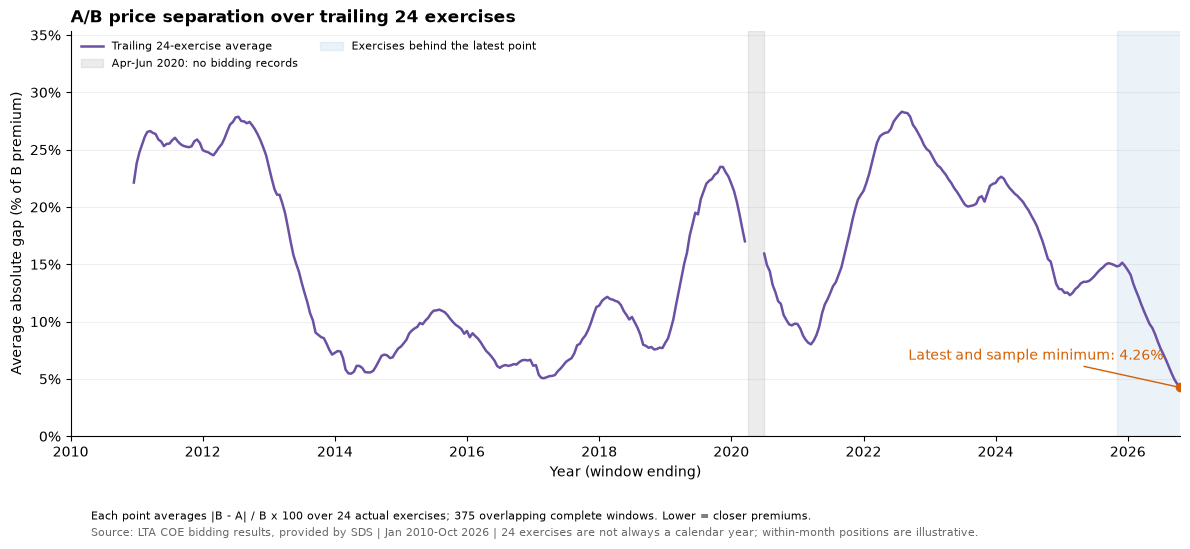

In [28]:
rolling_gap_months = pd.date_range(
    rolling_separation["month"].min(), rolling_separation["month"].max(), freq="MS"
)
rolling_gap_index = pd.MultiIndex.from_product(
    [rolling_gap_months, [1, 2]], names=["month", "bidding_no"]
)
rolling_gap_plot = rolling_separation.set_index(["month", "bidding_no"])[
    ["mean_abs_gap_pct_24"]
].reindex(rolling_gap_index).reset_index()
rolling_gap_month_duration = (
    rolling_gap_plot["month"] + pd.offsets.MonthBegin(1) - rolling_gap_plot["month"]
)
rolling_gap_plot["plot_date"] = (
    rolling_gap_plot["month"]
    + rolling_gap_month_duration * (rolling_gap_plot["bidding_no"] - 1) / 2
)

rolling_gap_fig, rolling_gap_ax = plt.subplots(figsize=(12, 5.5))
rolling_gap_ax.plot(
    rolling_gap_plot["plot_date"],
    rolling_gap_plot["mean_abs_gap_pct_24"].to_numpy(dtype=float, na_value=np.nan),
    color="#6A51A3", linewidth=1.8, label="Trailing 24-exercise average",
)
rolling_gap_ax.axvspan(
    pd.Timestamp("2020-04-01"), pd.Timestamp("2020-07-01"),
    color="grey", alpha=0.15, label="Apr-Jun 2020: no bidding records",
)
latest_window_start = history.iloc[-RECENT_WINDOW]["month"]
rolling_gap_ax.axvspan(
    latest_window_start, history.iloc[-1]["month"] + pd.offsets.MonthBegin(1),
    color="#0072B2", alpha=0.08, label="Exercises behind the latest point",
)
latest_plot_date = rolling_gap_plot["plot_date"].iloc[-1]
rolling_gap_ax.scatter([latest_plot_date], [latest_separation], color="#D55E00", s=35, zorder=5)
rolling_gap_ax.annotate(
    f"Latest and sample minimum: {latest_separation:.2f}%",
    xy=(latest_plot_date, latest_separation), xytext=(-12, 20),
    textcoords="offset points", ha="right", color="#D55E00", fontsize=10,
    arrowprops={"arrowstyle": "-", "color": "#D55E00"},
)
rolling_gap_ax.set_title(
    "A/B price separation over trailing 24 exercises", loc="left", fontweight="bold"
)
rolling_gap_ax.set_xlabel("Year (window ending)")
rolling_gap_ax.set_ylabel("Average absolute gap (% of B premium)")
rolling_gap_ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.0f}%"))
rolling_gap_ax.xaxis.set_major_locator(mdates.YearLocator(2))
rolling_gap_ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
rolling_gap_ax.set_ylim(0, rolling_separation["mean_abs_gap_pct_24"].max() * 1.25)
rolling_gap_ax.set_xlim(rolling_gap_plot["plot_date"].min(), latest_plot_date)
rolling_gap_ax.grid(axis="y", alpha=0.2)
rolling_gap_ax.spines[["top", "right"]].set_visible(False)
rolling_gap_ax.legend(loc="upper left", frameon=False, fontsize=8, ncol=2)
rolling_gap_fig.text(
    0.08, 0.045,
    "Each point averages |B - A| / B x 100 over 24 actual exercises; "
    "375 overlapping complete windows. Lower = closer premiums.",
    fontsize=8,
)
rolling_gap_fig.text(
    0.08, 0.015,
    "Source: LTA COE bidding results, provided by SDS | Jan 2010-Oct 2026 | "
    "24 exercises are not always a calendar year; within-month positions are illustrative.",
    fontsize=8, color="dimgray",
)
rolling_gap_fig.tight_layout(rect=(0, 0.09, 1, 1))
plt.show()

**Takeaway:** Average price separation has narrowed and widened repeatedly. The latest trailing 24-exercise average is 4.26%, the lowest among all 375 complete windows in this sample. This describes historical closeness, not a forecast or proof of a permanent change; adjacent points reuse 23 of the same exercises.

**Conclusion for this stage:** The latest 24 exercises have the smallest mean absolute percentage gap of all 375 complete trailing 24-exercise windows in this dataset (4.26%). This is strong descriptive evidence of unusually close premiums over that window, not proof of an enduring structural change. Earlier close-gap periods were followed by widening, and the latest dollar gap remains variable. The sample ends in October 2026, so the future path is unobserved.

**Status before Section 5.4:** At this descriptive stage we have not estimated the onset of the recent convergence, tested a structural break, or demonstrated stationarity or mean reversion. A formal method must account for serial dependence and any search over candidate break dates. The recent window is not assumed to begin at a 2014/2022 policy date. Similar COE prices also do not by themselves prove that the categories contain cars of similar value, since this table does not identify vehicle OMVs or individual models.

### 5.4 Did the gap shift to a lower level?

**Main result:** The gap has fallen, but the best dividing date depends on how much history we analyse. All periods end in October 2026.

| Starting point | Best split (first exercise under the lower fitted mean) |
| --- | --- |
| May 2022 | March 2024, exercise 1 |
| January 2024 | February 2026, exercise 1 |
| January 2025 | February 2026, exercise 1 |

**How it works:** Try each possible date, calculate the average gap before and after it, and choose the split that fits best. Require at least **12 exercises on each side**. Use the original gaps, not rolling averages.

To assess whether ordinary fluctuations could produce an equally strong split, compare it with **4,999 simulated histories**. Simulations rearrange chunks of **6 consecutive exercises**; repeat with chunks of 3 and 12 to check sensitivity. These chunk lengths are separate from the analysis periods above.

May 2022 is the main starting point because the current category definitions began then. Later starts focus on recent history; all these comparisons are exploratory.

In [29]:
BREAK_MIN_SEGMENT = 12
BREAK_BOOTSTRAPS = 4_999
BREAK_BLOCK_LENGTHS = [3, 6, 12]
BREAK_MAIN_BLOCK = 6
BREAK_SEED = SEED + 540
BREAK_STARTS = {
    "Current definition (primary)": pd.Timestamp("2022-05-01"),
    "From Jan 2024 (sensitivity)": pd.Timestamp("2024-01-01"),
    "From Jan 2025 (sensitivity)": pd.Timestamp("2025-01-01"),
}
BREAK_METRICS = {
    "Percentage gap (% of B)": "gap_pct_of_b",
    "Dollar gap (S$)": "gap_sgd",
}

def mean_shift_scan(values, min_segment=BREAK_MIN_SEGMENT):
    """Error-reduction fractions for all admissible two-mean splits.

    Accept a series or a matrix with one series per row. A split k puts
    observations 0..k-1 before the break and k..n-1 after the break.
    """
    values = np.atleast_2d(np.asarray(values, dtype=float))
    if values.ndim != 2 or not np.isfinite(values).all():
        raise ValueError("The mean-shift scan needs finite numeric observations.")
    n_obs = values.shape[1]
    if min_segment < 2 or n_obs < 2 * min_segment:
        raise ValueError("Insufficient observations for the requested segment lengths.")
    splits = np.arange(min_segment, n_obs - min_segment + 1)
    centered = values - values.mean(axis=1, keepdims=True)
    total_error = np.sum(centered ** 2, axis=1, keepdims=True)
    cumulative = np.cumsum(centered, axis=1)[:, splits - 1]
    # Between-segment sum of squares = improvement over one fitted mean.
    improvement = n_obs * cumulative ** 2 / (splits * (n_obs - splits))
    fractions = np.divide(
        improvement, total_error,
        out=np.zeros_like(improvement), where=total_error > 0,
    )
    return fractions, splits


def circular_block_scan_pvalue(values, observed_stat, block_length, rng):
    """Approximate stable-mean null using circular blocks; repeat the full scan."""
    values = np.asarray(values, dtype=float)
    n_obs = len(values)
    n_blocks = int(np.ceil(n_obs / block_length))
    starts = rng.integers(0, n_obs, size=(BREAK_BOOTSTRAPS, n_blocks))
    indices = (starts[:, :, None] + np.arange(block_length)) % n_obs
    indices = indices.reshape(BREAK_BOOTSTRAPS, -1)[:, :n_obs]
    bootstrap_series = (values - values.mean())[indices]
    bootstrap_scores, _ = mean_shift_scan(bootstrap_series)
    bootstrap_maxima = bootstrap_scores.max(axis=1)
    return (1 + np.count_nonzero(bootstrap_maxima >= observed_stat)) / (BREAK_BOOTSTRAPS + 1)

In [30]:
break_estimate_rows = []
break_test_rows = []
break_scan_details = {}

for sample_id, (sample, start_month) in enumerate(BREAK_STARTS.items()):
    frame = history.loc[history["month"] >= start_month].reset_index(drop=True)
    for metric_id, (metric, column) in enumerate(BREAK_METRICS.items()):
        values = frame[column].to_numpy(dtype=float)
        scores, splits = mean_shift_scan(values)
        best_position = int(np.argmax(scores[0]))
        split = int(splits[best_position])
        observed_stat = float(scores[0, best_position])
        before_mean = float(values[:split].mean())
        after_mean = float(values[split:].mean())
        break_estimate_rows.append({
            "sample": sample,
            "metric": metric,
            "exercises": len(frame),
            "candidate_first_after": exercise_label(frame.iloc[split]),
            "before_n": split,
            "after_n": len(frame) - split,
            "before_mean": before_mean,
            "after_mean": after_mean,
            "change_after_minus_before": after_mean - before_mean,
            "fit_error_reduction_pct": observed_stat * 100,
        })
        break_scan_details[(sample, metric)] = {
            "frame": frame, "splits": splits, "scores": scores[0], "split": split,
        }
        for block_length in BREAK_BLOCK_LENGTHS:
            # Independent reproducible streams for every setting.
            rng = np.random.default_rng(
                np.random.SeedSequence([BREAK_SEED, sample_id, metric_id, block_length])
            )
            pvalue = circular_block_scan_pvalue(values, observed_stat, block_length, rng)
            break_test_rows.append({
                "sample": sample,
                "metric": metric,
                "block_exercises": block_length,
                "p_search_adjusted": pvalue,
                "mc_standard_error": np.sqrt(pvalue * (1 - pvalue) / (BREAK_BOOTSTRAPS + 1)),
            })

break_estimates = pd.DataFrame(break_estimate_rows)
break_tests = pd.DataFrame(break_test_rows)
# Six series/sample searches are reported. Adjust separately at each block setting.
break_family_size = len(break_estimates)
break_tests["p_bonferroni_six_searches"] = (
    break_tests["p_search_adjusted"] * break_family_size
).clip(upper=1)
break_estimates.round(3)

,sample,metric,exercises,candidate_first_after,before_n,after_n,before_mean,after_mean,change_after_minus_before,fit_error_reduction_pct
0,Current definition (primary),Percentage gap (% of B),108,2024-03 / 1,44,64,22.758,9.773,-12.985,55.326
1,Current definition (primary),Dollar gap (S$),108,2024-03 / 1,44,64,26159.295,11238.094,-14921.202,49.355
2,From Jan 2024 (sensitivity),Percentage gap (% of B),68,2026-02 / 1,50,18,13.780,1.709,-12.071,60.008
3,From Jan 2024 (sensitivity),Dollar gap (S$),68,2026-02 / 1,50,18,15498.300,2126.167,-13372.133,58.364
4,From Jan 2025 (sensitivity),Percentage gap (% of B),44,2026-02 / 1,26,18,14.641,1.709,-12.932,74.580
5,From Jan 2025 (sensitivity),Dollar gap (S$),44,2026-02 / 1,26,18,17587.500,2126.167,-15461.333,75.896


**Reading the tables:** Before/after means describe each fitted period. Dollar-gap changes are in S$; percentage-gap changes are in percentage points. Fit-error reduction measures how much better two averages fit than one.

Smaller **p-values** indicate stronger evidence against a stable average gap under the simulation assumptions. The next table applies an extra conservative adjustment because we report six related searches. A p-value does not measure the chance that the selected date is correct.

In [31]:
break_pvalues = break_tests.pivot(
    index=["sample", "metric"], columns="block_exercises", values="p_search_adjusted"
).rename(columns=lambda length: f"p_block_{length}")
break_pvalues.columns.name = None
break_pvalues.round(4)

p_block_3  p_block_6  \
sample                       metric                                          
Current definition (primary) Dollar gap (S$)             0.0002     0.0008   
                             Percentage gap (% of B)     0.0002     0.0004   
From Jan 2024 (sensitivity)  Dollar gap (S$)             0.0002     0.0014   
                             Percentage gap (% of B)     0.0002     0.0018   
From Jan 2025 (sensitivity)  Dollar gap (S$)             0.0002     0.0072   
                             Percentage gap (% of B)     0.0006     0.0076   

                                                      p_block_12  
sample                       metric                               
Current definition (primary) Dollar gap (S$)              0.0140  
                             Percentage gap (% of B)      0.0096  
From Jan 2024 (sensitivity)  Dollar gap (S$)              0.0190  
                             Percentage gap (% of B)      0.0176  
From Jan 2025 (sensitivity)  Dollar gap (S$)              0.0316  
                             Percentage gap (% of B)      0.0414

In [32]:
break_adjusted_pvalues = break_tests.pivot(
    index=["sample", "metric"], columns="block_exercises", values="p_bonferroni_six_searches"
).rename(columns=lambda length: f"p_bonferroni_block_{length}")
break_adjusted_pvalues.columns.name = None
break_adjusted_pvalues.round(4)

p_bonferroni_block_3  \
sample                       metric                                          
Current definition (primary) Dollar gap (S$)                        0.0012   
                             Percentage gap (% of B)                0.0012   
From Jan 2024 (sensitivity)  Dollar gap (S$)                        0.0012   
                             Percentage gap (% of B)                0.0012   
From Jan 2025 (sensitivity)  Dollar gap (S$)                        0.0012   
                             Percentage gap (% of B)                0.0036   

                                                      p_bonferroni_block_6  \
sample                       metric                                          
Current definition (primary) Dollar gap (S$)                        0.0048   
                             Percentage gap (% of B)                0.0024   
From Jan 2024 (sensitivity)  Dollar gap (S$)                        0.0084   
                             Percentage gap (% of B)                0.0108   
From Jan 2025 (sensitivity)  Dollar gap (S$)                        0.0432   
                             Percentage gap (% of B)                0.0456   

                                                      p_bonferroni_block_12  
sample                       metric                                          
Current definition (primary) Dollar gap (S$)                         0.0840  
                             Percentage gap (% of B)                 0.0576  
From Jan 2024 (sensitivity)  Dollar gap (S$)                         0.1140  
                             Percentage gap (% of B)                 0.1056  
From Jan 2025 (sensitivity)  Dollar gap (S$)                         0.1896  
                             Percentage gap (% of B)                 0.2484

**Check the 12-exercise rule:** Repeat the fit requiring 18 or 24 exercises on each side. Requiring more post-change observations can force the dividing date earlier. These rows show alternative dates, not additional significance tests.

In [33]:
break_segment_rows = []
for sample, start_month in BREAK_STARTS.items():
    frame = history.loc[history["month"] >= start_month].reset_index(drop=True)
    for metric, column in BREAK_METRICS.items():
        values = frame[column].to_numpy(dtype=float)
        for min_segment in [12, 18, 24]:
            if len(frame) < 2 * min_segment:
                continue
            scores, splits = mean_shift_scan(values, min_segment=min_segment)
            split = int(splits[int(np.argmax(scores[0]))])
            break_segment_rows.append({
                "sample": sample,
                "metric": metric,
                "min_exercises_each_side": min_segment,
                "candidate_first_after": exercise_label(frame.iloc[split]),
                "before_n": split,
                "after_n": len(frame) - split,
            })
break_segment_sensitivity = pd.DataFrame(break_segment_rows)
break_segment_sensitivity

,sample,metric,min_exercises_each_side,candidate_first_after,before_n,after_n
0,Current definition (primary),Percentage gap (% of B),12,2024-03 / 1,44,64
1,Current definition (primary),Percentage gap (% of B),18,2024-03 / 1,44,64
2,Current definition (primary),Percentage gap (% of B),24,2024-03 / 1,44,64
3,Current definition (primary),Dollar gap (S$),12,2024-03 / 1,44,64
4,Current definition (primary),Dollar gap (S$),18,2024-03 / 1,44,64
5,Current definition (primary),Dollar gap (S$),24,2024-03 / 1,44,64
6,From Jan 2024 (sensitivity),Percentage gap (% of B),12,2026-02 / 1,50,18
7,From Jan 2024 (sensitivity),Percentage gap (% of B),18,2026-02 / 1,50,18
8,From Jan 2024 (sensitivity),Percentage gap (% of B),24,2025-10 / 1,42,26
9,From Jan 2024 (sensitivity),Dollar gap (S$),12,2026-02 / 1,50,18


**Read the chart:** Using January 2024 onwards, the purple line shows actual gaps. Blue and orange lines show fitted averages before and after the selected split. They are not forecasts.

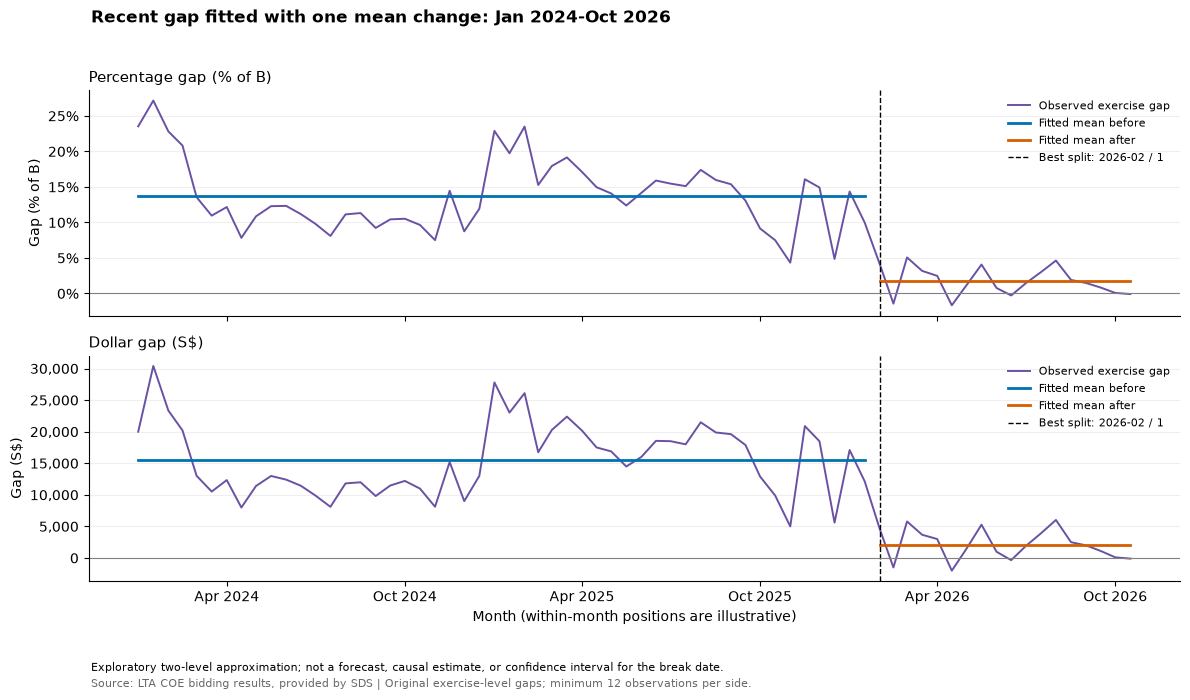

In [34]:
recent_break_sample = "From Jan 2024 (sensitivity)"
break_fig, break_axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

for ax, (metric, column) in zip(break_axes, BREAK_METRICS.items()):
    detail = break_scan_details[(recent_break_sample, metric)]
    frame = detail["frame"]
    split = detail["split"]
    month_duration = frame["month"] + pd.offsets.MonthBegin(1) - frame["month"]
    x = frame["month"] + month_duration * ((frame["bidding_no"].to_numpy(dtype=float) - 1) / 2)
    y = frame[column].to_numpy(dtype=float)
    ax.plot(x, y, color="#6A51A3", linewidth=1.4, label="Observed exercise gap")
    ax.plot(x.iloc[:split], np.full(split, y[:split].mean()),
            color="#0072B2", linewidth=2, label="Fitted mean before")
    ax.plot(x.iloc[split:], np.full(len(y) - split, y[split:].mean()),
            color="#D55E00", linewidth=2, label="Fitted mean after")
    ax.axvline(x.iloc[split], color="black", linestyle="--", linewidth=1,
               label=f"Best split: {exercise_label(frame.iloc[split])}")
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_title(metric, loc="left", fontsize=11)
    ax.set_ylabel("Gap (% of B)" if column == "gap_pct_of_b" else "Gap (S$)")
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.0f}%" if column == "gap_pct_of_b" else "{x:,.0f}"))
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper right", frameon=False, fontsize=8)

break_axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=6))
break_axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
break_axes[1].set_xlabel("Month (within-month positions are illustrative)")
break_fig.suptitle("Recent gap fitted with one mean change: Jan 2024-Oct 2026",
                   x=0.08, ha="left", fontweight="bold")
break_fig.text(0.08, 0.035,
               "Exploratory two-level approximation; not a forecast, causal estimate, or confidence interval for the break date.",
               fontsize=8)
break_fig.text(0.08, 0.012,
               "Source: LTA COE bidding results, provided by SDS | Original exercise-level gaps; minimum 12 observations per side.",
               fontsize=8, color="dimgray")
break_fig.tight_layout(rect=(0, 0.08, 1, 0.96))
plt.show()

<details>
<summary>Technical assumptions and method references (optional)</summary>

The test compares one constant mean with two constant means. It selects the largest reduction in squared fitting error. Every circular block-bootstrap replicate repeats the entire date search; p = (1 + equally or more extreme replicates) / 5,000. Blocks resample the globally demeaned series and wrap around its ends. The six-search adjustment is Bonferroni, applied separately at each block length.

Calibration assumes stationary, weakly dependent fluctuations under the stable-mean null; this assumption has not been established. Trends, changing variance, long dependence and multiple changes can affect results. These exploratory comparisons do not provide confidence intervals for dates or causal effects. Longer blocks give few effective blocks in short samples.

References: [Andrews: unknown-date searches](https://users.ssc.wisc.edu/~behansen/718/Andrews1993.pdf); [Politis and Romano: circular block resampling](https://statistics.stanford.edu/technical-reports/circular-block-resampling-procedure-stationary-data). This implementation uses bootstrap calibration rather than Andrews' tabulated critical values.

</details>

**Takeaway:** In the January 2024-onwards sample, the best split is February 2026: the fitted average gap falls from **S$15,498 to S$2,126**, or **13.78% to 1.71% of B**. Using the longer May 2022-onwards sample identifies an earlier split in March 2024 instead.

The main simulation setting supports a change. However, combining longer simulation chunks with the conservative six-search adjustment weakens the evidence beyond the usual 5% cutoff. Requiring more observations on each side also changes the recent date.

**There is evidence of narrowing, but its exact start and permanence remain uncertain.** Only 18 exercises follow the February 2026 split. A gradual decline or several changes could also produce this result; it does not establish the cause.

### 5.5 Did convergence come from A rising or B falling?

**Method and why:** Compare the average premium for each category in the same two non-overlapping 24-exercise windows used in 5.1. Decompose the change in the signed gap using `(change in B) - (change in A)`. This identifies how the narrowing happened arithmetically; it does not identify its cause.

In [35]:
previous_premiums = comparison_groups["Previous 24 exercises"]
latest_premiums = comparison_groups["Latest 24 exercises"]
premium_change_rows = []
for category in ["a", "b"]:
    previous_mean = float(previous_premiums[f"premium_{category}"].mean())
    latest_mean = float(latest_premiums[f"premium_{category}"].mean())
    premium_change_rows.append({
        "category": f"Category {category.upper()}",
        "previous_24_mean_sgd": previous_mean,
        "latest_24_mean_sgd": latest_mean,
        "increase_sgd": latest_mean - previous_mean,
        "increase_pct": (latest_mean / previous_mean - 1) * 100,
    })
premium_changes = pd.DataFrame(premium_change_rows).set_index("category")
premium_changes.round(2)

,previous_24_mean_sgd,latest_24_mean_sgd,increase_sgd,increase_pct
category,,,,
Category A,100656.29,118855.71,18199.42,18.08
Category B,118297.46,123750.38,5452.92,4.61


In [36]:
a_premium_increase = float(premium_changes.loc["Category A", "increase_sgd"])
b_premium_increase = float(premium_changes.loc["Category B", "increase_sgd"])
previous_signed_gap = float(previous_premiums["gap_sgd"].mean())
latest_signed_gap = float(latest_premiums["gap_sgd"].mean())
gap_change_from_premiums = b_premium_increase - a_premium_increase
assert np.isclose(gap_change_from_premiums, latest_signed_gap - previous_signed_gap)

print("Comparison: Nov 2024-Oct 2025 versus Nov 2025-Oct 2026 (24 exercises each).")
print(f"A's average premium increased by S${a_premium_increase:,.0f}.")
print(f"B's average premium increased by S${b_premium_increase:,.0f}.")
print(f"Change in average signed gap = B increase - A increase = S${gap_change_from_premiums:,.0f}.")
print(f"Average signed B-A gap: S${previous_signed_gap:,.0f} to S${latest_signed_gap:,.0f}.")

Comparison: Nov 2024-Oct 2025 versus Nov 2025-Oct 2026 (24 exercises each).
A's average premium increased by S$18,199.
B's average premium increased by S$5,453.
Change in average signed gap = B increase - A increase = S$-12,746.
Average signed B-A gap: S$17,641 to S$4,895.


**Takeaway:** Both categories became more expensive, but A rose much faster. Its average premium increased from **S$100,656 to S$118,856**, while B increased from **S$118,297 to S$123,750**. The narrowing therefore reflects **A catching up with B**, rather than B becoming cheaper.

The current split recently provided much less COE price advantage for A. Closer premiums have not meant cheaper COEs for its buyers in these windows. This is about nominal COE prices, not total car affordability: vehicle prices, taxes, incomes and financing are not measured here. The arithmetic does not establish why A rose or what a merger would cost.

### 5.6 Does the conclusion depend on choosing 24 exercises?

**Method and why:** Repeat the recent-closeness comparison with windows of **6, 12, 18, 24, 36 and 48 exercises**. For each length, compare the latest average absolute percentage gap with every historical window of that same length. Rank 1 means no earlier window had a smaller value, within numerical precision.

This checks the choice of window length, not the probability of future convergence. Windows overlap, different lengths answer different duration questions, and historical windows span different category definitions. These exploratory comparisons are not independent statistical tests. Six exercises are roughly three months; 48 are roughly two years, except when bidding is suspended.

In [37]:
ROBUSTNESS_WINDOWS = [6, 12, 18, 24, 36, 48]
absolute_percentage_gap = history["gap_pct_of_b"].abs()
window_robustness_rows = []

for window in ROBUSTNESS_WINDOWS:
    rolling_values = absolute_percentage_gap.rolling(window, min_periods=window).mean().dropna()
    latest_value = float(rolling_values.iloc[-1])
    smaller_windows = int(rolling_values.lt(latest_value - 1e-10).sum())
    window_robustness_rows.append({
        "window_exercises": window,
        "latest_window_start": exercise_label(history.iloc[-window]),
        "latest_window_end": exercise_label(history.iloc[-1]),
        "latest_mean_abs_gap_pct": latest_value,
        "historical_minimum_pct": float(rolling_values.min()),
        "rank_smallest_first": smaller_windows + 1,
        "complete_windows": len(rolling_values),
    })
window_robustness = pd.DataFrame(window_robustness_rows).set_index("window_exercises")
window_robustness.round(3)

,latest_window_start,latest_window_end,latest_mean_abs_gap_pct,historical_minimum_pct,rank_smallest_first,complete_windows
window_exercises,,,,,,
6,2026-08 / 1,2026-10 / 2,1.501,1.291,2,393
12,2026-05 / 1,2026-10 / 2,1.643,1.643,1,387
18,2026-02 / 1,2026-10 / 2,2.092,2.092,1,381
24,2025-11 / 1,2026-10 / 2,4.258,4.258,1,375
36,2025-05 / 1,2026-10 / 2,7.438,5.584,42,363
48,2024-11 / 1,2026-10 / 2,9.604,6.152,109,351


**Takeaway:** The latest **12-, 18- and 24-exercise** windows have the smallest average absolute percentage gaps among all historical windows of their respective lengths: **1.64%, 2.09% and 4.26%**. The latest 6-exercise window is second-smallest, so recent closeness does not depend only on choosing 24 exercises.

However, the latest **36- and 48-exercise** windows are not historical minima. The evidence supports unusually strong **recent** convergence, not an unprecedented multi-year pattern or permanent convergence.

## 6. Visualisations

Figures accompany the relevant analyses in Sections 4 and 5. The two selected trend figures used in the integrated team analysis are reproduced in Section 6.1 and Section 6.2 of [main.ipynb](main.ipynb).

## 7. Key Findings & Recommendation

**Scope:** Austin's trend-analysis workstream. The final team recommendation must also consider vehicle-value evidence and the merger/feebate simulation.

**Recommendation:** The unusually small recent gap supports reviewing whether the engine/power-based split still provides a meaningful COE price advantage for mass-market buyers, but convergence alone does not justify merging A and B. Support a merger and value-based feebate only if the team's simulation shows better protection for those buyers across plausible price assumptions; otherwise revise the proposed design before endorsing it.

**Key findings:**
1. **Recent convergence is broad, not one unusual result.** The latest 24 exercises have an average absolute gap of **S$5,224**, versus **S$17,641** in the preceding 24. In the latest window, **19 of 24 exercises** have premiums within 5% of B's price.
2. **A caught up with B through higher prices.** Average A premiums rose from **S$100,656 to S$118,856**, while B rose from **S$118,297 to S$123,750**. The weakening of A's COE price advantage has not meant cheaper COEs for A buyers.
3. **The finding survives several window lengths.** The latest 12-, 18- and 24-exercise average absolute percentage gaps are historical minima for those lengths. Longer 36- and 48-exercise windows are not, so the claim is specifically about recent convergence.
4. **Durability remains uncertain.** Earlier close-gap periods later widened. Structural-break results support narrowing under some settings, but the chosen dates and strength of evidence depend on the period, minimum segment length and simulation assumptions.
5. **Similar premiums do not establish similar vehicle values.** These auction results alone cannot show that A and B contain equally expensive cars or that a merger would improve buyers' outcomes.

## 8. Assumptions & Limitations

**What the data shows:**
- COE price separation has recently narrowed substantially across several window lengths.
- Both categories' average premiums rose; A rose faster in the previous-versus-latest 24-exercise comparison.
- Earlier small-gap periods were followed by widening. The post-February-2026 period contains only 18 exercises.

**What we assumed:**
- The percentage gap uses B's premium as its denominator; absolute gaps measure separation regardless of direction.
- Exercises receive equal weight. Windows count actual exercises, not fixed calendar years; absent April-June 2020 results are not filled.
- Near-zero thresholds (1%, 2%, 5%), historical block boundaries and recent-period starting dates are exploratory analytical choices.
- The break test approximates the history with two mean levels and assumes stationary, weakly dependent fluctuations under its null. Results are sensitive to the simulation block length and minimum observations on each side.

**What is speculation:**
- That EV adoption, model tuning or another particular factor caused the recent convergence.
- That the smaller gap will persist, or that merging categories will make COEs cheaper for mass-market buyers. Those claims are not established here.

**Limitations:**
- The data ends in October 2026; future persistence is unobserved. Category definitions differ across the historical sample.
- No individual bids, buyer incomes, model-level OMVs, total vehicle costs or controls for changing quotas and market conditions are used. Premium convergence does not demonstrate equivalent car values or improved affordability.
- Overlapping windows reuse observations. Historical ranks are descriptive, not independent significance evidence.
- The break analysis was developed after inspecting the charts. It does not identify a precise causal onset date, establish policy effects, or prove stationarity or mean reversion.
- A merged auction price is unobserved. The team must use clearly stated assumptions and sensitivity analysis to assess merger and feebate outcomes.

## 9. Data Sources & Declarations

| Dataset | Provider | Local file | Coverage |
| --- | --- | --- | --- |
| COE bidding results | LTA; supplied by SDS | `data/COEBiddingResultsPrices.csv` | Jan 2010-Oct 2026 |
| New car registrations by make | LTA; supplied by SDS | `data/NewRegistrationofCarsbyMake.csv` | Jan 2016-May 2025 |

Original acquisition dates were not recorded. Registrations receive basic cleaning; the trend calculations use COE data only. No additional numerical data or live API inputs are used.

**AI assistance:** OpenAI Codex supported data validation, analytical implementation, exploratory checks, plotting and documentation. The uncertainty and assumptions of the exploratory mean-shift procedure are stated with its results.

**Policy references (accessed 27 October 2026; used for event annotations, not extra numerical datasets):**
- [LTA vehicle statistics: definition regimes and the August 2012 taxi change](https://www.lta.gov.sg/content/dam/ltagov/who_we_are/statistics_and_publications/statistics/pdf/MVP02-1_New_Reg_by_COE.pdf).
- [LTA circular: May 2022 EV maximum-power revision](https://onemotoring.lta.gov.sg/content/dam/onemotoring/pdf/Circulars%20to%20ESAs/2022/VRL_04_2022.pdf).


**Statistical method references (accessed 27 October 2026):**
- [Andrews (1993): unknown-date structural-change tests](https://users.ssc.wisc.edu/~behansen/718/Andrews1993.pdf).
- [Politis and Romano: circular block resampling for stationary data](https://statistics.stanford.edu/technical-reports/circular-block-resampling-procedure-stationary-data).